In [1]:
import warnings; warnings.filterwarnings('ignore')

import pandas, seaborn as sns

import matplotlib.pyplot as plt

salesurl = '/content/train.csv'

In [2]:
sales = pandas.read_table(salesurl, sep=',')

sales.shape

(9800, 17)

In [3]:
sales.iloc[:5, :9]

,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city
0,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson
1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson
2,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles
3,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale
4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale


In [4]:
sales.iloc[:5, 9:]

,state,postal_code,region,product_id,category,sub_category,product_name,sales
0,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


Melakukan Inspeksi Apakah Kolom Tanggal Order & Tanggal Pengiriman Sudah Tipe Data Date

In [5]:
sales.order_date.dtype

dtype('O')

In [6]:
# sales['order_date'] = pandas.to_datetime(sales['order_date'], format = '%d/%m/%Y')

sales['order_date'] = pandas.to_datetime(sales['order_date'], format='ISO8601')

sales.order_date.dtype

dtype('<M8[ns]')

In [7]:
sales.order_date.iloc[:5]

,order_date
0,2017-11-08
1,2017-11-08
2,2017-06-12
3,2016-10-11
4,2016-10-11


In [8]:
sales.ship_date.dtype

dtype('O')

In [9]:
sales['ship_date'] = pandas.to_datetime(sales['ship_date'], format = '%d/%m/%Y', errors = 'coerce')

sales.ship_date.dtype

dtype('<M8[ns]')

Melakuka Inspeksi Pada Kolom Sales

In [10]:
sales.sales.dtype

dtype('float64')

In [11]:
float(sales.sales.sum())

2261536.7827000003

*Total Penjualan Kumulatif Sejauh ini Adalah : $ 2.225.138,92*

In [12]:
jumlah_penjualan_tabel = sales['order_id'].nunique()

jumlah_penjualan_tabel

4922

In [13]:
jumlah_penjualan_yearly = sales.groupby([sales['order_date'].dt.year])['order_id'].nunique()

jumlah_penjualan_yearly = pandas.DataFrame(jumlah_penjualan_yearly)

jumlah_penjualan_yearly.index.name = 'Year'

jumlah_penjualan_yearly.columns = ['Total']

In [14]:
jumlah_penjualan_yearly['Yearly'] = jumlah_penjualan_yearly['Total'].pct_change() * 100

jumlah_penjualan_yearly['Yearly'] = jumlah_penjualan_yearly['Yearly'].fillna(0)

jumlah_penjualan_yearly

,Total,Yearly
Year,,
2015,947,0.000000
2016,1019,7.602957
2017,1295,27.085378
2018,1661,28.262548


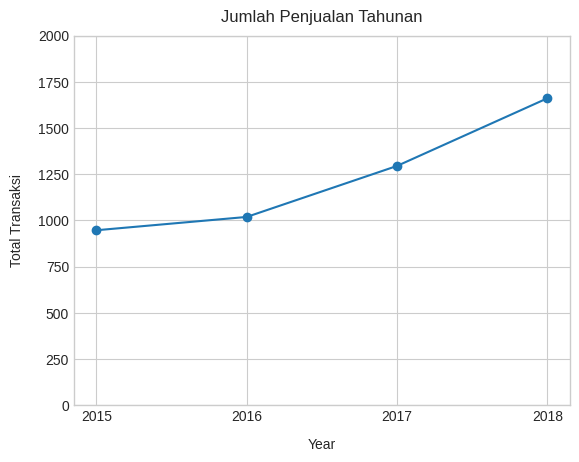

In [15]:
plt.style.use('seaborn-v0_8-whitegrid')

ax = jumlah_penjualan_yearly['Total'].plot.line(marker = 'o')

ax.set_title('Jumlah Penjualan Tahunan', pad = 10)

ax.set_xlabel('Year', labelpad=10)

ax.set_ylabel('Total Transaksi', labelpad=10)

ax.set_xticks(jumlah_penjualan_yearly.index)

ax.set_ylim(0, 2000)

plt.show()

In [16]:
total_penjualan_yearly = sales.groupby([sales['order_date'].dt.year])['sales'].sum()

total_penjualan_yearly = pandas.DataFrame(total_penjualan_yearly)

total_penjualan_yearly.index.name = 'Year'

total_penjualan_yearly.columns = ['Total Sales']

total_penjualan_yearly

,Total Sales
Year,
2015,479856.2081
2016,459436.0054
2017,600192.5500
2018,722052.0192


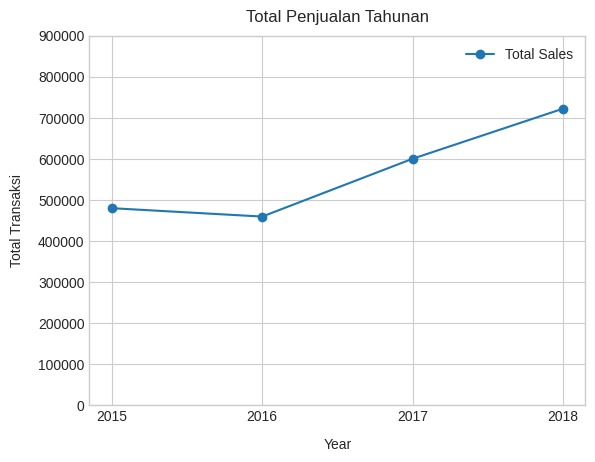

In [17]:
plt.style.use('seaborn-v0_8-whitegrid')

ax = total_penjualan_yearly.plot.line(marker = 'o')

ax.set_title('Total Penjualan Tahunan', pad = 10)

ax.set_xlabel('Year', labelpad=10)

ax.set_ylabel('Total Transaksi', labelpad=10)

ax.set_xticks(total_penjualan_yearly.index)

ax.set_ylim(0, 900000)

plt.show()